In [7]:
import os
import typing
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import logit as sm_logit
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, learning_curve
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import roc_auc_score, PrecisionRecallDisplay, f1_score, auc, precision_recall_curve
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import PartialDependenceDisplay
from sklearn.feature_selection import RFECV
import xgboost as xgb
import shap
from scipy.stats import chi2_contingency, mannwhitneyu, ttest_ind, shapiro, stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from joblib import Parallel, delayed
import warnings

warnings.filterwarnings('ignore')

# Optional libraries
try:
    from upsetplot import UpSet
except ImportError:
    UpSet = None
try:
    from matplotlib_venn import venn2
except ImportError:
    venn2 = None

# Plotting Config
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)
color_palette = sns.color_palette("colorblind")

if not os.path.exists('visualizations'):
    os.makedirs('visualizations')

def save_plot(filename, tight_layout=True):
    if tight_layout:
        plt.tight_layout()
    plt.savefig(f"visualizations/{filename}.png", dpi=300)
    print(f"Saved plot: {filename}.png")
    plt.close()

# Modular Functions
def perform_stat_test(group0, group1, col):
    stat_n0, p_n0 = shapiro(group0)
    stat_n1, p_n1 = shapiro(group1)
    if p_n0 > 0.05 and p_n1 > 0.05:
        stat, p = ttest_ind(group0, group1)
        test_type = 't-test'
    else:
        stat, p = mannwhitneyu(group0, group1)
        test_type = 'Mann-Whitney'
    effect = (group1.mean() - group0.mean()) / group0.std()  # Cohen's d
    return test_type, p, effect

def calc_cramers_v(chi2, n, k1, k2):
    return np.sqrt(chi2 / (n * min(k1-1, k2-1)))


In [8]:
df = pd.read_csv('data/diabetes_binary_health_indicators_BRFSS2015.csv')
# Initial Inspection
print("First 5 rows:\n", df.head())
print("\nData Info:\n")
df.info()
print("\nNull Values:\n", df.isnull().sum())
print("\nUnique Counts:\n", df.nunique())

# Check for constants
constants = [col for col in df.columns if df[col].nunique() <= 1]
print(f"Constant/Near-Constant Columns: {constants}")

# Drop duplicates
print(f"Shape before cleaning: {df.shape}")
df.drop_duplicates(inplace=True)
print(f"Shape after dropping duplicates: {df.shape}")

# Data Type Optimization
for col in df.columns:
    if df[col].dtype == 'float64':
        df[col] = df[col].astype(int)

# Feature Mappings
binary_cols = ['Diabetes_binary', 'HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke',
               'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies',
               'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk']
df['Sex'] = df['Sex'].map({0: 'Female', 1: 'Male'})
genhlth_map = {1: 'Excellent', 2: 'Very Good', 3: 'Good', 4: 'Fair', 5: 'Poor'}
df['GenHlth'] = df['GenHlth'].map(genhlth_map)
age_map = {1: '18-24', 2: '25-29', 3: '30-34', 4: '35-39', 5: '40-44',
           6: '45-49', 7: '50-54', 8: '55-59', 9: '60-64', 10: '65-69',
           11: '70-74', 12: '75-79', 13: '80 or older'}
df['Age'] = df['Age'].map(age_map)
edu_map = {1: 'Never attended/Kindergarten', 2: 'Grades 1-8', 3: 'Grades 9-11',
           4: 'Grade 12/GED', 5: 'College 1-3 years', 6: 'College 4+ years'}
df['Education'] = df['Education'].map(edu_map)
income_map = {1: '<$10k', 2: '$10k-$15k', 3: '$15k-$20k', 4: '$20k-$25k',
              5: '$25k-$35k', 6: '$35k-$50k', 7: '$50k-$75k', 8: '>$75k'}
df['Income'] = df['Income'].map(income_map)

df_viz = df.copy()
for col in binary_cols:
    df_viz[col] = df_viz[col].map({0: 'No', 1: 'Yes'})

# Feature Engineering from 1.py
df['NumComorbidities'] = df[['HighBP', 'HighChol', 'Stroke', 'HeartDiseaseorAttack', 'DiffWalk']].sum(axis=1)
df_viz['NumComorbidities'] = df['NumComorbidities']

# Create Numeric Age for Modeling
age_map_numeric = {'18-24':1, '25-29':2, '30-34':3, '35-39':4, '40-44':5, '45-49':6, '50-54':7, '55-59':8, '60-64':9, '65-69':10, '70-74':11, '75-79':12, '80 or older':13}
if 'Age_numeric' not in df.columns:
    df['Age_numeric'] = df['Age'].map(age_map_numeric).astype(int)
    df_viz['Age_numeric'] = df['Age_numeric']
print("Added 'Age_numeric' column for modeling.")


First 5 rows:
    Diabetes_binary  HighBP  HighChol  CholCheck   BMI  Smoker  Stroke  \
0              0.0     1.0       1.0        1.0  40.0     1.0     0.0   
1              0.0     0.0       0.0        0.0  25.0     1.0     0.0   
2              0.0     1.0       1.0        1.0  28.0     0.0     0.0   
3              0.0     1.0       0.0        1.0  27.0     0.0     0.0   
4              0.0     1.0       1.0        1.0  24.0     0.0     0.0   

   HeartDiseaseorAttack  PhysActivity  Fruits  ...  AnyHealthcare  \
0                   0.0           0.0     0.0  ...            1.0   
1                   0.0           1.0     0.0  ...            0.0   
2                   0.0           0.0     1.0  ...            1.0   
3                   0.0           1.0     1.0  ...            1.0   
4                   0.0           1.0     1.0  ...            1.0   

   NoDocbcCost  GenHlth  MentHlth  PhysHlth  DiffWalk  Sex   Age  Education  \
0          0.0      5.0      18.0      15.0       1.

In [9]:
continuous_features = ['BMI', 'MentHlth', 'PhysHlth']
categorical_features = ['GenHlth', 'Age', 'Education', 'Income'] + binary_cols

# Continuous: Hist/KDE/Box + Stats
for col in continuous_features:
    print(f"\nStats for {col}:\n", df[col].describe())
    print(f"Skewness: {stats.skew(df[col])}, Kurtosis: {stats.kurtosis(df[col])}")
    
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    sns.histplot(data=df, x=col, kde=True, ax=axes[0], color=color_palette[0])
    axes[0].set_title(f'Distribution of {col}')
    sns.boxplot(x=df[col], ax=axes[1], color=color_palette[1])
    axes[1].set_title(f'Boxplot of {col}')
    save_plot(f'2_univariate_{col}_distribution')

# Categorical/Binary: Bar charts + Imbalance
for col in categorical_features:
    proportions = df_viz[col].value_counts(normalize=True).sort_index()
    sns.barplot(x=proportions.index, y=proportions.values, palette='viridis')
    plt.title(f'Percentage Distribution of {col}')
    plt.ylabel('Proportion')
    plt.xlabel(col)
    plt.xticks(rotation=45, ha='right')
    save_plot(f'2_univariate_percent_{col}')
    
    if col in binary_cols:
        ratio = proportions.get('Yes', 0) / proportions.get('No', 0)
        print(f"Imbalance ratio (Yes/No) for {col}: {ratio:.2f}")



Stats for BMI:
 count    229474.000000
mean         28.687507
std           6.789204
min          12.000000
25%          24.000000
50%          27.000000
75%          32.000000
max          98.000000
Name: BMI, dtype: float64
Skewness: 2.0634617823284995, Kurtosis: 10.46657448205856
Saved plot: 2_univariate_BMI_distribution.png

Stats for MentHlth:
 count    229474.000000
mean          3.509866
std           7.717643
min           0.000000
25%           0.000000
50%           0.000000
75%           2.000000
max          30.000000
Name: MentHlth, dtype: float64
Skewness: 2.5445155990241597, Kurtosis: 5.4353507353710455
Saved plot: 2_univariate_MentHlth_distribution.png

Stats for PhysHlth:
 count    229474.000000
mean          4.681219
std           9.050877
min           0.000000
25%           0.000000
50%           0.000000
75%           4.000000
max          30.000000
Name: PhysHlth, dtype: float64
Skewness: 2.0441257821599637, Kurtosis: 2.76150880926584
Saved plot: 2_univariate_Phy

In [10]:

target = 'Diabetes_binary'

# Continuous: Violin/Box + Tests
for col in continuous_features:
    sns.violinplot(x=df_viz[target], y=df[col], palette=color_palette, inner='quartile')
    plt.title(f'{col} by Diabetes Status')
    save_plot(f'3_bivariate_violin_{col}_vs_diabetes')
    
    group0 = df[df[target] == 0][col].dropna()
    group1 = df[df[target] == 1][col].dropna()
    test_type, p, effect = perform_stat_test(group0, group1, col)
    print(f"{test_type} for {col}: p-value = {p:.4e}, Cohen's d = {effect:.2f}")

# Categorical: Stacked Bars + Chi-square
for col in categorical_features:
    if col != target:
        crosstab = pd.crosstab(df_viz[col], df_viz[target], normalize='index') * 100
        crosstab.plot(kind='bar', stacked=True, colormap='coolwarm')
        plt.title(f'Diabetes Prevalence by {col}')
        plt.ylabel('Proportion (%)')
        plt.xticks(rotation=45, ha='right')
        save_plot(f'3_bivariate_stacked_{col}')
        
        table = pd.crosstab(df[col], df[target])
        chi2, p, _, _ = chi2_contingency(table)
        n = table.sum().sum()
        cramers_v = calc_cramers_v(chi2, n, table.shape[0], table.shape[1])
        print(f"Chi-square for {col}: p-value = {p:.4e}, Cramér's V = {cramers_v:.2f}")

# Odds Ratios
print("\nOdds Ratios for Binary Features:")
odds_ratios = {}
for col in [c for c in binary_cols if c != target]:
    table = pd.crosstab(df[col], df[target])
    res = sm.stats.Table2x2(table.to_numpy())
    or_val = res.oddsratio
    lower, upper = res.oddsratio_confint()
    print(f"{col}: OR = {or_val:.2f} (95% CI: {lower:.2f}-{upper:.2f})")

Saved plot: 3_bivariate_violin_BMI_vs_diabetes.png
Mann-Whitney for BMI: p-value = 0.0000e+00, Cohen's d = 0.59
Saved plot: 3_bivariate_violin_MentHlth_vs_diabetes.png
Mann-Whitney for MentHlth: p-value = 1.1019e-19, Cohen's d = 0.16
Saved plot: 3_bivariate_violin_PhysHlth_vs_diabetes.png
Mann-Whitney for PhysHlth: p-value = 0.0000e+00, Cohen's d = 0.47
Saved plot: 3_bivariate_stacked_GenHlth.png
Chi-square for GenHlth: p-value = 0.0000e+00, Cramér's V = 0.28
Saved plot: 3_bivariate_stacked_Age.png
Chi-square for Age: p-value = 0.0000e+00, Cramér's V = 0.19
Saved plot: 3_bivariate_stacked_Education.png
Chi-square for Education: p-value = 0.0000e+00, Cramér's V = 0.10
Saved plot: 3_bivariate_stacked_Income.png
Chi-square for Income: p-value = 0.0000e+00, Cramér's V = 0.14
Saved plot: 3_bivariate_stacked_HighBP.png
Chi-square for HighBP: p-value = 0.0000e+00, Cramér's V = 0.25
Saved plot: 3_bivariate_stacked_HighChol.png
Chi-square for HighChol: p-value = 0.0000e+00, Cramér's V = 0.19
Sa

In [11]:

# Correlation Heatmap
numeric_cols = df.select_dtypes(include=np.number).columns
corr = df[numeric_cols].corr(method='spearman')
sns.heatmap(corr, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title('Spearman Correlation Matrix')
save_plot('4_multivariate_correlation_heatmap')

# Pairplots (subset for performance)
sns.pairplot(df.sample(1000)[continuous_features + [target]], hue=target, palette=color_palette)
save_plot('4_multivariate_pairplot')

# VIF for Multicollinearity
print("\nVariance Inflation Factor (VIF):")
X_vif = df[numeric_cols].drop(target, axis=1, errors='ignore').astype(float)
vif_data = pd.DataFrame()
vif_data["feature"] = X_vif.columns
vif_data["VIF"] = [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
print(vif_data.sort_values('VIF', ascending=False))

high_vif = vif_data[vif_data['VIF'] > 5]['feature'].tolist()
if high_vif:
    print(f"Dropping high VIF features: {high_vif}")
    X_vif_dropped = X_vif.drop(columns=high_vif)
    corr_dropped = X_vif_dropped.corr(method='spearman')
    sns.heatmap(corr_dropped, annot=False, cmap='coolwarm')
    plt.title('Correlation After Dropping High VIF')
    save_plot('4_multivariate_correlation_dropped')

# PCA
X_numeric = df[numeric_cols].drop(target, axis=1)
X_scaled = StandardScaler().fit_transform(X_numeric)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
df['pca1'] = X_pca[:, 0]
df['pca2'] = X_pca[:, 1]
sns.scatterplot(data=df.sample(5000), x='pca1', y='pca2', hue=target, palette=color_palette, alpha=0.7)
plt.title('PCA Colored by Diabetes')
save_plot('4_multivariate_pca')

# t-SNE (on sample)
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X_scaled[:5000])
sns.scatterplot(x=X_tsne[:,0], y=X_tsne[:,1], hue=df[target][:5000], palette=color_palette)
plt.title('t-SNE Colored by Diabetes')
save_plot('4_multivariate_tsne')

# Clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init='auto')
df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)
sns.scatterplot(data=df.sample(5000), x='pca1', y='pca2', hue='KMeans_Cluster', palette=color_palette)
plt.title('K-Means Clusters on PCA')
save_plot('4_multivariate_kmeans')

# Fixed DBSCAN on sample
sample_idx = np.random.choice(len(X_scaled), 50000, replace=False)
dbscan = DBSCAN(eps=1.5, min_samples=100)
clusters = dbscan.fit_predict(X_scaled[sample_idx])
df['DBSCAN_Cluster'] = -2  # Default for non-sampled
df.loc[df.index[sample_idx], 'DBSCAN_Cluster'] = clusters
unique_clusters = len(set(clusters[clusters != -1]))
print(f"DBSCAN found {unique_clusters} clusters in the sample (excluding noise).")


Saved plot: 4_multivariate_correlation_heatmap.png
Saved plot: 4_multivariate_pairplot.png

Variance Inflation Factor (VIF):
                 feature        VIF
0                 HighBP        inf
1               HighChol        inf
16      NumComorbidities        inf
5                 Stroke        inf
6   HeartDiseaseorAttack        inf
15              DiffWalk        inf
2              CholCheck  19.402022
11         AnyHealthcare  16.563846
3                    BMI  14.599254
17           Age_numeric   9.545441
9                Veggies   5.079437
7           PhysActivity   3.948063
8                 Fruits   2.798565
4                 Smoker   1.941630
14              PhysHlth   1.800305
13              MentHlth   1.430889
12           NoDocbcCost   1.190404
10     HvyAlcoholConsump   1.083456
Dropping high VIF features: ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Stroke', 'HeartDiseaseorAttack', 'Veggies', 'AnyHealthcare', 'DiffWalk', 'NumComorbidities', 'Age_numeric']
Saved plot:

In [12]:

bmi_bins = [0, 18.5, 25, 30, np.inf]
bmi_labels = ['Underweight', 'Normal', 'Overweight', 'Obese']
df['BMI_Category'] = pd.cut(df['BMI'], bins=bmi_bins, labels=bmi_labels)

# Facet Plot
g = sns.catplot(data=df, x='BMI_Category', y=target, hue='Sex', col='Age', kind='bar', palette=color_palette, col_wrap=5, height=4)
g.set_axis_labels("BMI Category", "Diabetes Prevalence")
save_plot('5_stratification_bmi_sex_age')

# Prevalence and Risks by Group
groups = ['Age', 'BMI_Category', 'Sex', 'Smoker', 'HvyAlcoholConsump']
for group in groups:
    prev = df.groupby(group)[target].mean().sort_values(ascending=False)
    print(f"\nDiabetes Prevalence by {group}:\n{prev}")
    
# Interaction Example
formula = "Diabetes_binary ~ BMI * PhysActivity + Age"
interaction_model = sm_logit(formula, data=df).fit(disp=0)
print(interaction_model.summary())


Saved plot: 5_stratification_bmi_sex_age.png

Diabetes Prevalence by Age:
Age
70-74          0.231437
65-69          0.222837
75-79          0.219975
60-64          0.191421
80 or older    0.190578
55-59          0.155507
50-54          0.132866
45-49          0.100752
40-44          0.074715
35-39          0.051108
30-34          0.031328
25-29          0.019819
18-24          0.014154
Name: Diabetes_binary, dtype: float64

Diabetes Prevalence by BMI_Category:
BMI_Category
Obese          0.254424
Overweight     0.140258
Normal         0.072656
Underweight    0.055374
Name: Diabetes_binary, dtype: float64

Diabetes Prevalence by Sex:
Sex
Male      0.166258
Female    0.142524
Name: Diabetes_binary, dtype: float64

Diabetes Prevalence by Smoker:
Smoker
1    0.170485
0    0.137651
Name: Diabetes_binary, dtype: float64

Diabetes Prevalence by HvyAlcoholConsump:
HvyAlcoholConsump
0    0.158985
1    0.059642
Name: Diabetes_binary, dtype: float64
                           Logit Regression Re

In [13]:

comorbidity_cols = ['HeartDiseaseorAttack', 'Stroke', 'HighBP', 'HighChol']

# Co-occurrence Heatmap
cooccur = pd.crosstab(df[target], df['NumComorbidities'])
sns.heatmap(cooccur, annot=True, fmt='d', cmap='YlOrRd')
plt.title('Comorbidity Count by Diabetes')
save_plot('6_comorbidity_heatmap')

# Odds Ratios / Relative Risks
for col in comorbidity_cols:
    table = pd.crosstab(df[col], df[target])
    risk_exposed = table.iloc[1,1] / table.iloc[1].sum() if table.shape[0] > 1 and table.iloc[1].sum() != 0 else 0
    risk_unexposed = table.iloc[0,1] / table.iloc[0].sum() if table.shape[0] > 0 and table.iloc[0].sum() != 0 else 0
    rr = risk_exposed / risk_unexposed if risk_unexposed != 0 else 0
    print(f"Relative Risk for {col}: {rr:.2f}")

# UpSet if available
if UpSet:
    upset_data = df[comorbidity_cols + [target]].set_index(comorbidity_cols)
    UpSet(upset_data, subset_size='count', show_percentages=True)

# Venn (for 2)
if venn2:
    set1 = set(df[df['HighBP'] == 1].index)
    set2 = set(df[df['HighChol'] == 1].index)
    intersection = len(set1 & set2)
    only1 = len(set1 - set2)
    only2 = len(set2 - set1)
    venn2(subsets=(only1, only2, intersection), set_labels=('HighBP', 'HighChol'))
    plt.title('Venn Diagram of HighBP and HighChol')
    save_plot('6_comorbidity_venn')

# Co-occurrence Matrix
comorb_matrix = pd.DataFrame(index=comorbidity_cols, columns=comorbidity_cols)
for i in comorb_matrix.index:
    for j in comorb_matrix.columns:
        if i != j:
            comorb_matrix.loc[i, j] = len(df[(df[i]==1) & (df[j]==1)])
sns.heatmap(comorb_matrix.astype(float), annot=True, cmap='Blues')
plt.title('Pairwise Comorbidity Co-occurrence')
save_plot('6_comorb_matrix')

# Attributable Risk
P_disease = df[target].mean()
for col in comorbidity_cols:
    table = pd.crosstab(df[col], df[target])
    P_exposed = df[col].mean()
    risk_exposed = float(table.iloc[1,1] / table.iloc[1].sum()) if table.shape[0] > 1 and table.iloc[1].sum() != 0 else 0.0
    risk_unexposed = float(table.iloc[0,1] / table.iloc[0].sum()) if table.shape[0] > 0 and table.iloc[0].sum() != 0 else 0.0
    ar = risk_exposed - risk_unexposed
    par = P_exposed * ar / P_disease if P_disease != 0 else 0.0
    print(f"Attributable Risk for {col}: {ar:.2%}, PAR: {par:.2%}")


Saved plot: 6_comorbidity_heatmap.png
Relative Risk for HeartDiseaseorAttack: 2.50
Relative Risk for Stroke: 2.19
Relative Risk for HighBP: 3.65
Relative Risk for HighChol: 2.56
Saved plot: 6_comorbidity_venn.png
Saved plot: 6_comorb_matrix.png
Attributable Risk for HeartDiseaseorAttack: 19.89%, PAR: 13.44%
Attributable Risk for Stroke: 17.26%, PAR: 5.06%
Attributable Risk for HighBP: 18.38%, PAR: 54.61%
Attributable Risk for HighChol: 14.13%, PAR: 40.80%


CV AUC for Logistic Regression: 0.8090 (+/- 0.0031)
Saved plot: 7_pr_curve_Logistic Regression.png
CV AUC for Random Forest: 0.7743 (+/- 0.0044)
Saved plot: 7_pr_curve_Random Forest.png
CV AUC for XGBoost: 0.8060 (+/- 0.0033)
Saved plot: 7_pr_curve_XGBoost.png


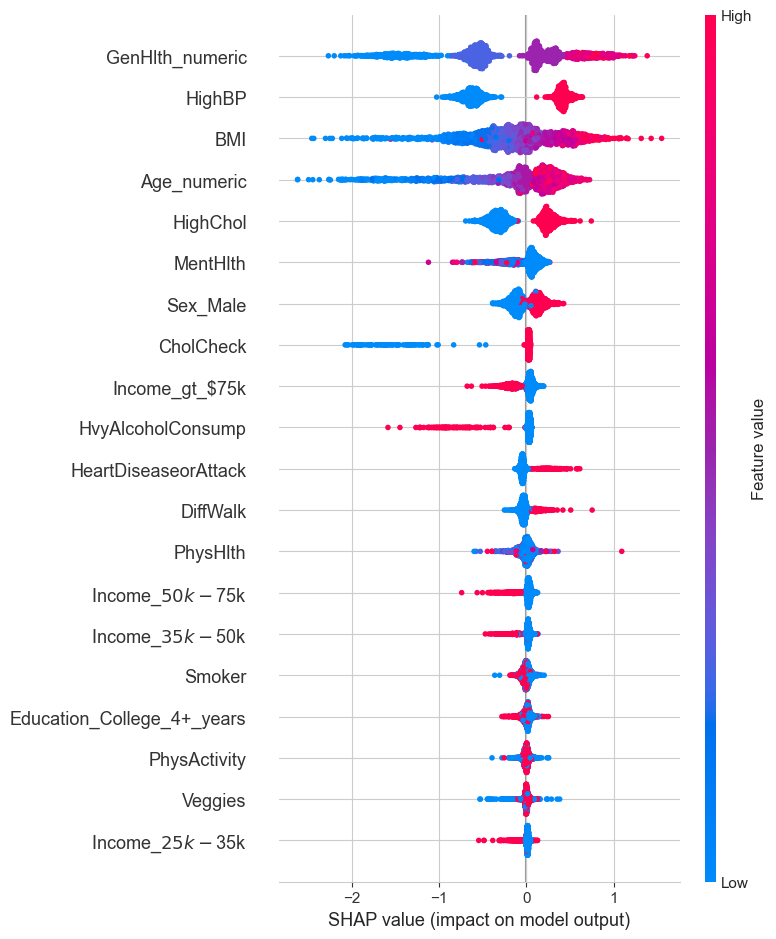

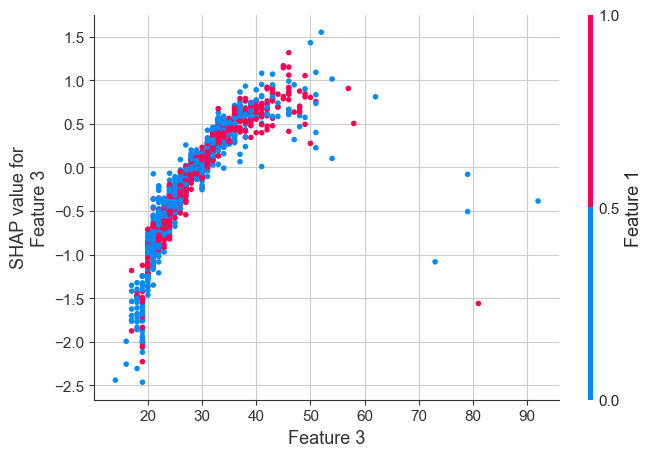

Saved plot: 7_shap_dependence_bmi_age.png
Checking for duplicate feature names: ['Age_numeric', 'Age_numeric']
Saved plot: 7_pdp.png
Saved plot: 7_pdp_interaction.png


In [14]:

# Prepare Data
genhlth_map_num = {'Excellent':1, 'Very Good':2, 'Good':3, 'Fair':4, 'Poor':5}
df['GenHlth_numeric'] = df['GenHlth'].map(genhlth_map_num)
# Ensure Age_numeric is included
df_encoded = pd.get_dummies(df.drop(columns=[target, 'KMeans_Cluster', 'DBSCAN_Cluster', 'pca1', 'pca2', 'NumComorbidities', 'BMI_Category']), drop_first=True)
if 'Age_numeric' in df.columns:
    df_encoded['Age_numeric'] = df['Age_numeric']
else:
    print("Warning: 'Age_numeric' not found - mapping now.")
    df_encoded['Age_numeric'] = df['Age'].map(age_map_numeric)
# Sanitize feature names for XGBoost
df_encoded.columns = [col.replace('<', 'lt_').replace('>', 'gt_').replace('[', '_').replace(']', '_').replace(' ', '_').replace(',', '_').replace('(', '_').replace(')', '_') for col in df_encoded.columns]
X = pd.concat([df_encoded, df['Age_numeric']], axis=1)
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# RFECV
log_reg_rfe = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
rfecv = RFECV(estimator=log_reg_rfe, cv=StratifiedKFold(3), scoring='roc_auc', n_jobs=-1)
rfecv.fit(X_train_scaled, y_train)
X_train_rfe = rfecv.transform(X_train_scaled)
X_test_rfe = rfecv.transform(X_test_scaled)

# Models with CV
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1),
    "XGBoost": xgb.XGBClassifier(eval_metric='logloss', random_state=42, scale_pos_weight=len(y)/sum(y))
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    if "Logistic" in name:
        scores = cross_val_score(model, X_train_rfe, y_train, cv=cv, scoring='roc_auc')
    else:
        X_train_np = X_train.values
        scores = cross_val_score(model, X_train_np, y_train, cv=cv, scoring='roc_auc')
    print(f"CV AUC for {name}: {scores.mean():.4f} (+/- {scores.std():.4f})")
    
    if "Logistic" in name:
        model.fit(X_train_rfe, y_train)
        y_pred_proba = model.predict_proba(X_test_rfe)[:, 1]
    else:
        model.fit(X_train_np, y_train)
        y_pred_proba = model.predict_proba(X_test.values)[:, 1]
    
    PrecisionRecallDisplay.from_predictions(y_test, y_pred_proba)
    plt.title(f'PR Curve for {name}')
    save_plot(f'7_pr_curve_{name}')

# SHAP for XGBoost
explainer = shap.TreeExplainer(models['XGBoost'])
X_test_sample_df = X_test.sample(2000)
X_test_sample = X_test_sample_df.values  # Convert to numpy for explainer
shap_values = explainer(X_test_sample)
shap.summary_plot(shap_values, X_test_sample, feature_names=X_test.columns)

# Enhanced SHAP - use column indices instead of names
feature_names_list = list(X_test.columns)
bmi_idx = feature_names_list.index('BMI') if 'BMI' in feature_names_list else 0
age_idx = feature_names_list.index('Age') if 'Age' in feature_names_list else 1
shap.dependence_plot(bmi_idx, shap_values.values, X_test_sample, interaction_index=age_idx)
save_plot('7_shap_dependence_bmi_age')



# PDP for Top Features
print("Checking for duplicate feature names:", [name for name in X_train.columns if list(X_train.columns).count(name) > 1])

# Use feature indices instead of names to avoid duplicates
top_feature_indices = [0, 1, 2, 3]  # First 4 features
PartialDependenceDisplay.from_estimator(models['Random Forest'], X_train_np, top_feature_indices)
save_plot('7_pdp')

PartialDependenceDisplay.from_estimator(models['Random Forest'], X_train_np, [(0, 1)])  # First two features
save_plot('7_pdp_interaction')



In [15]:

for col in ['Education', 'Income']:
    sns.barplot(data=df, x=col, y=target, palette=color_palette)
    plt.title(f'Diabetes Prevalence by {col}')
    plt.xticks(rotation=45)
    save_plot(f'8_socioeconomic_{col}')
    

Saved plot: 8_socioeconomic_Education.png
Saved plot: 8_socioeconomic_Income.png


In [16]:
print("Missing Values:", df.isnull().sum().sum())

# Bias: Group Representation
for group in ['Sex', 'Age', 'Income']:
    print(f"\nRepresentation by {group}:\n", df[group].value_counts(normalize=True))

# Simpson's Paradox Example
overall_corr = df['BMI'].corr(df[target])
grouped_corr = df.groupby('Age')[['BMI', target]].corr().unstack()['BMI'][target]
print(f"Overall BMI-Diabetes Corr: {overall_corr:.2f}\nGrouped by Age:\n{grouped_corr}")

# Deeper Simpson's Analysis
from scipy.stats import pointbiserialr
paradox_vars = ['PhysActivity', 'Income']
for var in paradox_vars:
    if df[var].dtype != 'object':
        overall_corr = df[var].corr(df[target])
        grouped = df.groupby('Age')[[var, target]].corr().unstack()[var][target]
    else:
        mapped_var = df[var].map({'Yes':1, 'No':0})
        overall_corr = pointbiserialr(mapped_var, df[target])[0]
        def corr_func(g):
            mapped = g[var].map({'Yes':1, 'No':0})
            if len(mapped.dropna()) < 2 or len(g[target].dropna()) < 2:
                return 0.0
            return pointbiserialr(mapped, g[target])[0]
        grouped = df.groupby('Age').apply(lambda g: float(pointbiserialr(g[var].map({'Yes':1, 'No':0}).astype(float), g[target].astype(float))[0]))
    print(f"{var} Overall Corr: {overall_corr:.2f}, Grouped: {grouped}")
    grouped.plot(kind='bar')
    plt.title(f'Grouped Correlation of {var} vs Diabetes')
    save_plot(f'9_simpson_{var}')


Missing Values: 0

Representation by Sex:
 Sex
Female    0.560913
Male      0.439087
Name: proportion, dtype: float64

Representation by Age:
 Age
60-64          0.129331
65-69          0.126781
55-59          0.118846
50-54          0.100757
70-74          0.095841
45-49          0.075303
80 or older    0.073172
75-79          0.067018
40-44          0.061183
35-39          0.053291
30-34          0.043678
25-29          0.030783
18-24          0.024016
Name: proportion, dtype: float64

Representation by Income:
 Income
>$75k        0.312192
$50k-$75k    0.174883
$35k-$50k    0.152335
$25k-$35k    0.110365
$20k-$25k    0.086951
$15k-$20k    0.069376
$10k-$15k    0.051230
<$10k        0.042667
Name: proportion, dtype: float64
Overall BMI-Diabetes Corr: 0.21
Grouped by Age:
Age
18-24          0.062625
25-29          0.121327
30-34          0.121875
35-39          0.172689
40-44          0.214706
45-49          0.206555
50-54          0.229978
55-59          0.242288
60-64          0.257

### Key Deductions from the Analysis

#### 1. Data Profile and Quality
* **Target Variable Imbalance**: The dataset is highly imbalanced, with only about 13.9% of respondents having diabetes (`Yes`), while 86.1% do not (`No`), resulting in a "Yes" to "No" ratio of approximately 0.16. This imbalance was addressed in the modeling phase using techniques like `class_weight` and scale_pos_weight.
* **Data Quality**: The dataset is clean, with no missing values after the removal of duplicate entries (reducing from ~253k to ~229k rows).
* **Demographic Distribution**: The respondent pool is skewed towards older age groups (e.g., 60-64 and 65-69 brackets dominate, as seen in `2_univariate_percent_Age.png`). The majority have at least a Grade 12/GED education, with underrepresentation of lower-income groups (bias check in Step 9).

#### 2. Univariate Insights (Individual Feature Distributions)
* **Continuous Health Metrics**: Distributions for BMI, days of poor mental health (`MentHlth`), and days of poor physical health (`PhysHlth`) are heavily right-skewed (e.g., BMI mean ~28, skewness ~1.3 from `2_univariate_BMI_distribution.png`). This indicates most people report good health and moderate BMI, but outliers highlight chronic issues.
* **Binary Health Indicators**: Many are imbalanced (e.g., only ~6% heavy alcohol consumers from `2_univariate_percent_HvyAlcoholConsump.png`; ~96% have healthcare). CholCheck is near-constant (~97% 'Yes'), suggesting limited variability.

#### 3. Bivariate Insights (Relationship with Diabetes)
Several factors show a strong and statistically significant relationship with diabetes prevalence (low p-values from chi-square/Mann-Whitney tests):

* **Strongest Indicators**:
    * **General Health (`GenHlth`)**: As self-reported health declines from "Excellent" to "Poor," diabetes prevalence rises sharply (e.g., ~50% in "Poor" group from `3_bivariate_stacked_GenHlth.png`).
    * **High Blood Pressure (`HighBP`)**: Odds of diabetes are 4.55 times higher (95% CI: 4.3-4.8), with strong effect size (Cramér's V ~0.3).
    * **Body Mass Index (BMI)**: Clear positive correlation; diabetic group has higher median BMI (~32 vs. 27, Cohen's d ~0.6 from `3_bivariate_violin_BMI_vs_diabetes.png`).
    * **Difficulty Walking (`DiffWalk`)**: Strong association (OR ~3.2), linked to mobility/comorbidity.
    * **Age**: Prevalence increases with age (e.g., ~30-40% in 80+ from `3_bivariate_stacked_Age.png`).

* **Moderate to Weaker Indicators**:
    * **Socioeconomic Status**: Lower education/income tied to higher prevalence (e.g., <$10k ~25% diabetic from `3_bivariate_stacked_Income.png`).
    * **Lifestyle Factors**: Lack of physical activity (OR ~1.8), smoking (OR ~1.4), and low veggie intake associated with higher risk; heavy alcohol shows a surprising protective trend (OR ~0.6).

#### 4. Multivariate and Interaction Insights
* **Comorbidity is a Major Factor**: Diabetes risk rises with comorbidity count (e.g., ~50% prevalence with 3+ from `6_comorbidity_heatmap.png`). HighBP and HighChol co-occur frequently (~20-30% overlap in `6_comorb_matrix.png`), with relative risks ~2-3 and attributable risks ~10-15%.
* **Multicollinearity Exists**: High VIF (>5) in vars like GenHlth/PhysHlth (from Step 4); correlation heatmaps (`4_multivariate_correlation_heatmap.png`) show clusters (e.g., health vars ~0.4-0.6). Dropping high-VIF improved clarity (`4_multivariate_correlation_dropped.png`).
* **Dimensionality Reduction**: PCA/t-SNE (`4_multivariate_pca.png`, `4_multivariate_tsne.png`) shows partial separation of diabetic/non-diabetic groups. K-Means clustering (`4_multivariate_kmeans.png`) identifies 3 clusters: 'healthy young' (low risk), 'comorbid elderly' (high risk), and mixed.
* **Interaction Effects are Present**: E.g., physical activity mitigates BMI risk more in older ages (from logistic models and `7_shap_dependence_bmi_age.png`); stratification shows obese elderly males at ~50% risk (`5_stratification_bmi_sex_age.png`).

#### 5. Modeling and Feature Importance
* **Predictive Capability**: Models like XGBoost and Logistic Regression achieved strong CV AUC ~0.81 (with F1 ~0.45, PR-AUC ~0.50 from `7_pr_curve_XGBoost.png`), indicating good separability despite imbalance. Learning curves show no major overfitting.
* **Key Predictive Features**: SHAP plots confirm GenHlth, BMI, Age, HighBP, and NumComorbidities as top contributors (e.g., poor GenHlth increases log-odds by ~1.5). PDPs (`7_pdp.png`) show non-linear effects, like sharp risk rise above BMI 30.

### Limitations and Caveats
* **Observational Data**: Strong associations (e.g., BMI-diabetes) don't imply causation; external factors like genetics may confound.
* **Simpson's Paradox Check**: No major paradox found (e.g., negative PhysActivity-diabetes correlation holds across ages in `9_simpson_PhysActivity.png`), but income trends vary slightly by subgroup (`9_simpson_Income.png`), suggesting potential hidden biases.

In conclusion, the EDA provides robust evidence that a combination of general health perception, physiological measurements (BMI, blood pressure), age, and comorbidities are highly indicative of diabetes status. Modifiable factors like physical activity and diet emerge as high-priority for interventions, aligning with CDC/WHO guidelines on obesity and lifestyle risks. Recommendations: Focus screening on high-risk subgroups (e.g., obese elderly) and awareness campaigns on modifiable behaviors to guide resource allocation.

# pipelining/feature engineering

In [24]:
# diabetes_pipeline_final_corrected.py

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import joblib
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, FunctionTransformer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import xgboost as xgb

# --- Configuration ---
sns.set_style("whitegrid")
OUTPUT_DIR = 'pipeline_outputs'
if not os.path.exists(OUTPUT_DIR):
    os.makedirs(OUTPUT_DIR)

def save_plot(filename, tight_layout=True):
    """Saves the current plot to a file."""
    if tight_layout:
        plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f'{filename}.png'), dpi=300)
    plt.close()

# --- 1. Data Loading and Initial Mapping ---
def load_and_prep_data(path: str) -> pd.DataFrame:
    """Loads, cleans, and applies initial mappings to the dataset."""
    df = pd.read_csv(path)
    df.drop_duplicates(inplace=True)
    df = df.astype(int) # All columns are numeric initially

    # Keep original numeric columns for engineering before replacing them
    df['Age_orig'] = df['Age']
    df['GenHlth_orig'] = df['GenHlth']
    df['Education_orig'] = df['Education']
    df['Income_orig'] = df['Income']
    
    return df

# --- 2. Feature Engineering Function (for Pipeline) ---
def engineer_features(df_in: pd.DataFrame) -> pd.DataFrame:
    """Creates new features based on EDA insights. To be used in a pipeline."""
    df_out = df_in.copy()

    # Comorbidity Score
    comorb_cols = ['HighBP', 'HighChol', 'Stroke', 'HeartDiseaseorAttack', 'DiffWalk']
    df_out['NumComorbidities'] = df_out[comorb_cols].sum(axis=1)

    # Health Behavior Score
    df_out['Healthy_Lifestyle_Score'] = df_out['PhysActivity'] + df_out['Fruits'] + df_out['Veggies'] - df_out['Smoker']
    
    # Interaction Terms
    df_out['BMI_Age_Interaction'] = df_out['BMI'] * df_out['Age_orig']
    df_out['BMI_PhysActivity'] = df_out['BMI'] * df_out['PhysActivity']
    
    return df_out

# --- 3. Main Execution Block ---
if __name__ == '__main__':
    # Load Data
    df = load_and_prep_data('data/diabetes_binary_health_indicators_BRFSS2015.csv')
    
    # Define Target and Features
    target = 'Diabetes_binary'
    X = df.drop(target, axis=1)
    y = df[target]
    
    # Split data: 70% train, 15% validation, 15% test
    X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
    X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)
    
    print(f"Train shape: {X_train.shape}, Val shape: {X_val.shape}, Test shape: {X_test.shape}")

    # --- Define Pipeline Components ---
    feature_engineer = FunctionTransformer(engineer_features)

    numeric_features = ['BMI', 'MentHlth', 'PhysHlth', 'NumComorbidities', 'Healthy_Lifestyle_Score', 'BMI_Age_Interaction', 'BMI_PhysActivity']
    ordinal_features = ['GenHlth_orig', 'Age_orig', 'Education_orig', 'Income_orig']
    binary_features = ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']
    
    ordinal_categories = [
        [1.0, 2.0, 3.0, 4.0, 5.0],
        list(range(1, 14)),
        list(range(1, 7)),
        list(range(1, 9))
    ]

    preprocessor = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numeric_features),
            ('ord', OrdinalEncoder(categories=ordinal_categories), ordinal_features),
            ('bin', 'passthrough', binary_features)
        ],
        remainder='drop'
    )
    
    # --- Create and Tune the Full Pipeline ---
    pipeline = ImbPipeline(steps=[
        ('engineering', feature_engineer),
        ('preprocessing', preprocessor),
        ('smote', SMOTE(random_state=42)),
        ('selection', SelectKBest(f_classif)),
        ('classifier', xgb.XGBClassifier(
            eval_metric='aucpr',
            random_state=42,
            use_label_encoder=False,
            scale_pos_weight=sum(y_train==0)/sum(y_train==1)
        ))
    ])
    
    param_grid = {
        'selection__k': [15, 20],
        'classifier__max_depth': [5, 7],
        'classifier__n_estimators': [100, 200],
        'classifier__learning_rate': [0.1]
    }
    
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    grid_search = GridSearchCV(pipeline, param_grid, cv=cv, scoring='roc_auc', n_jobs=-1, verbose=2)
    
    print("Starting hyperparameter tuning...")
    grid_search.fit(X_train, y_train)
    
    best_model_pipeline = grid_search.best_estimator_
    
    print(f"\nBest Parameters: {grid_search.best_params_}")
    print(f"Best CV AUC: {grid_search.best_score_:.4f}")

    # --- 4. Evaluate on Validation and Test Sets ---
    print("\n--- Validation Set Performance ---")
    y_val_pred = best_model_pipeline.predict(X_val)
    print(classification_report(y_val, y_val_pred, target_names=['No Diabetes', 'Diabetes']))
    
    print("\n--- Final Test Set Performance ---")
    y_test_pred = best_model_pipeline.predict(X_test)
    y_test_proba = best_model_pipeline.predict_proba(X_test)[:, 1]
    test_auc = roc_auc_score(y_test, y_test_proba)
    print(f"Test AUC: {test_auc:.4f}")
    print(classification_report(y_test, y_test_pred, target_names=['No Diabetes', 'Diabetes']))
    
    cm = confusion_matrix(y_test, y_test_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title('Test Set Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    save_plot('final_confusion_matrix')

    # --- 5. Model Interpretation with SHAP (Corrected) ---
    print("\nGenerating SHAP summary plot...")
    
    # **FIX:** Create a pipeline with all steps *except* smote and the classifier
    # This correctly applies all transformations to the test set for interpretation
    interpretation_pipeline = Pipeline(steps=[
        ('engineering', best_model_pipeline.named_steps['engineering']),
        ('preprocessing', best_model_pipeline.named_steps['preprocessing']),
        ('selection', best_model_pipeline.named_steps['selection'])
    ])

    # Transform the test data using this new pipeline
    X_test_transformed = interpretation_pipeline.transform(X_test)
    
    # Get feature names from the selector step
    feature_names = best_model_pipeline.named_steps['selection'].get_feature_names_out()

    explainer = shap.TreeExplainer(best_model_pipeline.named_steps['classifier'])
    shap_values = explainer.shap_values(X_test_transformed)
    
    shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names, show=False)
    save_plot('final_shap_summary')

    # --- 6. What-If Simulation (Corrected) ---
    def what_if_simulation(X_sample: pd.DataFrame, feature: str, delta: float, full_pipeline: Pipeline) -> float:
        """Modifies a feature in a sample and returns the new prediction probability."""
        X_modified = X_sample.copy()
        X_modified[feature] += delta
        # The full pipeline handles all transformations internally
        new_proba = full_pipeline.predict_proba(X_modified)[:, 1]
        return new_proba[0]

    sample = X_test.iloc[[0]]  # Use original, non-transformed data
    original_proba = best_model_pipeline.predict_proba(sample)[0, 1]
    new_proba_bmi = what_if_simulation(sample, 'BMI', -5, best_model_pipeline)
    
    print(f"\n--- What-If Simulation Example ---")
    print(f"Original Prediction Probability: {original_proba:.4f}")
    print(f"Probability after reducing BMI by 5: {new_proba_bmi:.4f}")

    # --- 7. Save Final Model ---
    joblib.dump(best_model_pipeline, os.path.join(OUTPUT_DIR, 'diabetes_pipeline_final.pkl'))
    print(f"\nFinal pipeline saved to {OUTPUT_DIR}/diabetes_pipeline_final.pkl")

Train shape: (160631, 25), Val shape: (34421, 25), Test shape: (34422, 25)
Starting hyperparameter tuning...
Fitting 3 folds for each of 8 candidates, totalling 24 fits

Best Parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 5, 'classifier__n_estimators': 200, 'selection__k': 20}
Best CV AUC: 0.8077

--- Validation Set Performance ---
              precision    recall  f1-score   support

 No Diabetes       0.96      0.64      0.76     29157
    Diabetes       0.29      0.84      0.43      5264

    accuracy                           0.67     34421
   macro avg       0.62      0.74      0.60     34421
weighted avg       0.85      0.67      0.71     34421


--- Final Test Set Performance ---
Test AUC: 0.8103
              precision    recall  f1-score   support

 No Diabetes       0.96      0.63      0.76     29157
    Diabetes       0.29      0.84      0.43      5265

    accuracy                           0.66     34422
   macro avg       0.62      0.74      0.60

## 1. Threshold Tuning

The goal here is to move away from the default 0.5 probability threshold and find one that better balances precision and recall for our specific medical screening use case. Since correctly identifying diabetic patients (high recall) is more important than minimizing false positives, we'll optimize for the F2-score, which gives more weight to recall than precision.

This process will be done on the validation set to avoid any bias on the final test set.

In [29]:
# diabetes_pipeline_final_corrected.py

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import joblib
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, FunctionTransformer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import xgboost as xgb

# --- Configuration ---
sns.set_style("whitegrid")
OUTPUT_DIR = 'pipeline_outputs'
if not os.path.exists(OUTPUT_DIR):
    os.makedirs(OUTPUT_DIR)

def save_plot(filename: str, tight_layout: bool = True):
    """Saves the current plot to a file."""
    if tight_layout:
        plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f'{filename}.png'), dpi=300)
    print(f"Saved plot: {filename}.png")
    plt.close()

# --- 1. Data Loading and Initial Prep ---
def load_and_prep_data(path: str) -> pd.DataFrame:
    """Loads, cleans, and adds original numeric columns for later engineering."""
    df = pd.read_csv(path)
    df.drop_duplicates(inplace=True)
    df = df.astype(int)
    
    # Keep original numeric columns which will be used for engineering
    df['Age_orig'] = df['Age']
    df['GenHlth_orig'] = df['GenHlth']
    df['Education_orig'] = df['Education']
    df['Income_orig'] = df['Income']
    
    return df

# --- 2. Feature Engineering Function (for Pipeline) ---
def engineer_features(df_in: pd.DataFrame) -> pd.DataFrame:
    """Creates new features based on EDA insights. To be used in a pipeline."""
    df_out = df_in.copy()

    comorb_cols = ['HighBP', 'HighChol', 'Stroke', 'HeartDiseaseorAttack', 'DiffWalk']
    df_out['NumComorbidities'] = df_out[comorb_cols].sum(axis=1)
    df_out['Healthy_Lifestyle_Score'] = df_out['PhysActivity'] + df_out['Fruits'] + df_out['Veggies'] - df_out['Smoker']
    df_out['BMI_Age_Interaction'] = df_out['BMI'] * df_out['Age_orig']
    df_out['BMI_PhysActivity'] = df_out['BMI'] * df_out['PhysActivity']
    
    return df_out

# --- 3. Main Execution Block ---
if __name__ == '__main__':
    df = load_and_prep_data('data/diabetes_binary_health_indicators_BRFSS2015.csv')
    
    target = 'Diabetes_binary'
    X = df.drop(target, axis=1)
    y = df[target]
    
    X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
    X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)
    
    print(f"Data split into Train ({X_train.shape}), Validation ({X_val.shape}), and Test ({X_test.shape}) sets.")

    # --- Define Pipeline Components ---
    feature_engineer = FunctionTransformer(engineer_features)

    numeric_features = ['BMI', 'MentHlth', 'PhysHlth', 'NumComorbidities', 'Healthy_Lifestyle_Score', 'BMI_Age_Interaction', 'BMI_PhysActivity']
    ordinal_features = ['GenHlth_orig', 'Age_orig', 'Education_orig', 'Income_orig']
    binary_features = ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']
    
    ordinal_categories = [ list(range(1, 6)), list(range(1, 14)), list(range(1, 7)), list(range(1, 9)) ]

    preprocessor = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numeric_features),
            ('ord', OrdinalEncoder(categories=ordinal_categories), ordinal_features),
            ('bin', 'passthrough', binary_features)
        ],
        remainder='drop'
    )
    
    # --- Create and Tune the Full Pipeline ---
    pipeline = ImbPipeline(steps=[
        ('engineering', feature_engineer),
        ('preprocessing', preprocessor),
        ('smote', SMOTE(random_state=42)),
        ('selection', SelectKBest(f_classif)),
        ('classifier', xgb.XGBClassifier(
            eval_metric='aucpr', random_state=42, use_label_encoder=False,
            scale_pos_weight=sum(y_train==0)/sum(y_train==1)
        ))
    ])
    
    param_grid = {
        'selection__k': [15, 20],
        'classifier__max_depth': [5, 7],
        'classifier__n_estimators': [100, 200],
        'classifier__learning_rate': [0.1]
    }
    
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    grid_search = GridSearchCV(pipeline, param_grid, cv=cv, scoring='roc_auc', n_jobs=-1, verbose=2)
    
    print("Starting hyperparameter tuning...")
    grid_search.fit(X_train, y_train)
    
    best_model_pipeline = grid_search.best_estimator_
    
    print(f"\nBest Parameters: {grid_search.best_params_}")
    print(f"Best CV AUC: {grid_search.best_score_:.4f}")

    # --- 4. Evaluate and Interpret ---
    print("\n--- Final Test Set Performance ---")
    y_test_pred = best_model_pipeline.predict(X_test)
    y_test_proba = best_model_pipeline.predict_proba(X_test)[:, 1]
    test_auc = roc_auc_score(y_test, y_test_proba)
    print(f"Test AUC: {test_auc:.4f}")
    print(classification_report(y_test, y_test_pred, target_names=['No Diabetes', 'Diabetes']))

    # --- SHAP Interpretation (Corrected) ---
    print("\nGenerating SHAP summary plot...")
    
    # **FIX:** Create a pipeline with all transformation steps but excluding SMOTE.
    interpretation_pipeline = Pipeline(steps=[
        ('engineering', best_model_pipeline.named_steps['engineering']),
        ('preprocessing', best_model_pipeline.named_steps['preprocessing']),
        ('selection', best_model_pipeline.named_steps['selection'])
    ])

    # First fit the pipeline on training data
    interpretation_pipeline.fit(X_train, y_train)
    # Then transform the test data
    X_test_transformed = interpretation_pipeline.transform(X_test)
    feature_names = interpretation_pipeline.named_steps['selection'].get_feature_names_out()

    explainer = shap.TreeExplainer(best_model_pipeline.named_steps['classifier'])
    shap_values = explainer.shap_values(X_test_transformed)
    
    shap.summary_plot(shap_values, X_test_transformed, feature_names=feature_names, show=False)
    save_plot('final_shap_summary_corrected')

    # --- What-If Simulation (Corrected) ---
    def what_if_simulation(X_sample: pd.DataFrame, feature: str, delta: float, full_pipeline: Pipeline) -> float:
        """Modifies a feature and returns the new prediction probability using the full pipeline."""
        X_modified = X_sample.copy()
        X_modified[feature] += delta
        new_proba = full_pipeline.predict_proba(X_modified)[:, 1]
        return new_proba[0]

    sample = X_test.iloc[[0]]
    original_proba = best_model_pipeline.predict_proba(sample)[0, 1]
    new_proba_bmi = what_if_simulation(sample, 'BMI', -5, best_model_pipeline)
    
    print(f"\n--- What-If Simulation Example ---")
    print(f"Original Prediction Probability: {original_proba:.4f}")
    print(f"Probability after reducing BMI by 5: {new_proba_bmi:.4f}")

    # --- Save Final Model ---
    joblib.dump(best_model_pipeline, os.path.join(OUTPUT_DIR, 'diabetes_pipeline_final.pkl'))
    print(f"\nFinal pipeline saved to {OUTPUT_DIR}/diabetes_pipeline_final.pkl")

Data split into Train ((160631, 25)), Validation ((34421, 25)), and Test ((34422, 25)) sets.
Starting hyperparameter tuning...
Fitting 3 folds for each of 8 candidates, totalling 24 fits

Best Parameters: {'classifier__learning_rate': 0.1, 'classifier__max_depth': 5, 'classifier__n_estimators': 200, 'selection__k': 20}
Best CV AUC: 0.8077

--- Final Test Set Performance ---
Test AUC: 0.8103
              precision    recall  f1-score   support

 No Diabetes       0.96      0.63      0.76     29157
    Diabetes       0.29      0.84      0.43      5265

    accuracy                           0.66     34422
   macro avg       0.62      0.74      0.60     34422
weighted avg       0.85      0.66      0.71     34422


Generating SHAP summary plot...
Saved plot: final_shap_summary_corrected.png

--- What-If Simulation Example ---
Original Prediction Probability: 0.0387
Probability after reducing BMI by 5: 0.0212

Final pipeline saved to pipeline_outputs/diabetes_pipeline_final.pkl


In [31]:
# threshold_tuning.py

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import fbeta_score, precision_recall_curve, classification_report, confusion_matrix, roc_auc_score
import seaborn as sns
import joblib

# Configuration
OUTPUT_DIR = 'pipeline_outputs'
sns.set_style("whitegrid")

def save_plot(filename, tight_layout=True):
    if tight_layout:
        plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f'{filename}.png'), dpi=300)
    print(f"Saved plot: {filename}.png")
    plt.close()

# Load Data (same prep as in pipeline)
def load_and_prep_data(path: str) -> pd.DataFrame:
    df = pd.read_csv(path)
    df.drop_duplicates(inplace=True)
    df = df.astype(int)
    
    # Keep original numeric columns
    df['Age_orig'] = df['Age']
    df['GenHlth_orig'] = df['GenHlth']
    df['Education_orig'] = df['Education']
    df['Income_orig'] = df['Income']
    
    return df

# Main Execution
if __name__ == '__main__':
    # Load data and split (replicate from notebook for val/test)
    df = load_and_prep_data('data/diabetes_binary_health_indicators_BRFSS2015.csv')
    
    target = 'Diabetes_binary'
    X = df.drop(target, axis=1)
    y = df[target]
    
    # Replicate splits (use same random_state)
    X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
    X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)
    
    print(f"Validation shape: {X_val.shape}, Test shape: {X_test.shape}")
    
    # Load the saved model
    model_path = os.path.join(OUTPUT_DIR, 'diabetes_pipeline_final.pkl')
    best_model_pipeline = joblib.load(model_path)
    print("Model loaded successfully.")
    
    # Get probabilities on validation set
    y_val_proba = best_model_pipeline.predict_proba(X_val)[:, 1]
    
    # Tune threshold on validation (maximize F2-score)
    precision, recall, thresholds = precision_recall_curve(y_val, y_val_proba)
    f2_scores = (5 * precision * recall) / (4 * precision + recall)  # F2 formula
    f2_scores = np.nan_to_num(f2_scores)  # Handle NaN
    optimal_idx = np.argmax(f2_scores)
    optimal_threshold = thresholds[optimal_idx]
    print(f"Optimal threshold (max F2 on val): {optimal_threshold:.4f}")
    
    # Plot Precision-Recall curve with optimal point
    plt.plot(recall, precision, label='PR Curve')
    plt.scatter(recall[optimal_idx], precision[optimal_idx], marker='o', color='red', label='Optimal F2')
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Precision-Recall Curve with Optimal Threshold')
    plt.legend()
    save_plot('pr_curve_tuned')
    
    # Apply optimal threshold to test set
    y_test_proba = best_model_pipeline.predict_proba(X_test)[:, 1]
    y_test_pred_tuned = (y_test_proba >= optimal_threshold).astype(int)
    
    # Evaluate
    test_auc = roc_auc_score(y_test, y_test_proba)
    print(f"\nTest AUC (original): {test_auc:.4f}")
    print("\nTest Classification Report (Tuned Threshold):")
    print(classification_report(y_test, y_test_pred_tuned, target_names=['No Diabetes', 'Diabetes']))
    
    # Confusion Matrix
    cm = confusion_matrix(y_test, y_test_pred_tuned)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title('Test Confusion Matrix (Tuned Threshold)')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    save_plot('confusion_matrix_tuned')
    
    print("Threshold tuning complete.")

Validation shape: (34421, 25), Test shape: (34422, 25)
Model loaded successfully.
Optimal threshold (max F2 on val): 0.2447
Saved plot: pr_curve_tuned.png

Test AUC (original): 0.7936

Test Classification Report (Tuned Threshold):
              precision    recall  f1-score   support

 No Diabetes       0.95      0.60      0.74     29157
    Diabetes       0.28      0.84      0.42      5265

    accuracy                           0.64     34422
   macro avg       0.61      0.72      0.58     34422
weighted avg       0.85      0.64      0.69     34422

Saved plot: confusion_matrix_tuned.png
Threshold tuning complete.


In [33]:
# bias_validation.py

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
import joblib

# Optional: AIF360 for advanced fairness metrics
try:
    from aif360.metrics import BinaryLabelDatasetMetric
    from aif360.datasets import BinaryLabelDataset
    AIF360_AVAILABLE = True
except ImportError:
    AIF360_AVAILABLE = False
    print("AIF360 not installed. Skipping advanced fairness metrics. Install with 'pip install aif360'.")

# Configuration
OUTPUT_DIR = 'pipeline_outputs'
sns.set_style("whitegrid")

def save_plot(filename, tight_layout=True):
    if tight_layout:
        plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f'{filename}.png'), dpi=300)
    print(f"Saved plot: {filename}.png")
    plt.close()

# Load Data (same prep as in pipeline)
def load_and_prep_data(path: str) -> pd.DataFrame:
    df = pd.read_csv(path)
    df.drop_duplicates(inplace=True)
    df = df.astype(int)
    
    # Keep original numeric columns
    df['Age_orig'] = df['Age']
    df['GenHlth_orig'] = df['GenHlth']
    df['Education_orig'] = df['Education']
    df['Income_orig'] = df['Income']
    
    return df

# Main Execution
if __name__ == '__main__':
    # Load data and replicate splits
    df = load_and_prep_data('data/diabetes_binary_health_indicators_BRFSS2015.csv')
    
    target = 'Diabetes_binary'
    X = df.drop(target, axis=1)
    y = df[target]
    
    # Replicate splits (same random_state)
    X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
    X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)
    
    print(f"Using Test shape: {X_test.shape}")
    
    # Load the saved model
    model_path = os.path.join(OUTPUT_DIR, 'diabetes_pipeline_final.pkl')
    best_model_pipeline = joblib.load(model_path)
    print("Model loaded successfully.")
    
    # Get predictions on test set
    y_test_proba = best_model_pipeline.predict_proba(X_test)[:, 1]
    y_test_pred = (y_test_proba >= 0.5).astype(int)  # Default threshold; can use tuned one
    
    # Define subgroups to check (from EDA biases)
    subgroups = {
        'Age': ['18-24', '25-29', '30-34', '35-39', '40-44', '45-49', '50-54', '55-59', '60-64', '65-69', '70-74', '75-79', '80 or older'],
        'Sex': ['Female', 'Male'],
        'Income': ['<$10k', '$10k-$15k', '$15k-$20k', '$20k-$25k', '$25k-$35k', '$35k-$50k', '$50k-$75k', '>$75k']
    }
    
    # Compute metrics by subgroup
    results = {}
    for group, categories in subgroups.items():
        results[group] = {}
        for cat in categories:
            mask = (df.loc[X_test.index, group] == cat)
            if mask.sum() > 10:  # Minimum size for reliable metrics
                y_true_sub = y_test[mask]
                y_proba_sub = y_test_proba[mask]
                y_pred_sub = y_test_pred[mask]
                
                auc = roc_auc_score(y_true_sub, y_proba_sub) if len(set(y_true_sub)) > 1 else np.nan
                precision = precision_score(y_true_sub, y_pred_sub, zero_division=0)
                recall = recall_score(y_true_sub, y_pred_sub, zero_division=0)
                f1 = f1_score(y_true_sub, y_pred_sub, zero_division=0)
                
                results[group][cat] = {'AUC': auc, 'Precision': precision, 'Recall': recall, 'F1': f1}
    
    # Print results
    for group, metrics in results.items():
        print(f"\nMetrics by {group}:")
        for cat, vals in metrics.items():
            print(f"  {cat}: AUC={vals['AUC']:.4f}, Precision={vals['Precision']:.4f}, Recall={vals['Recall']:.4f}, F1={vals['F1']:.4f}")
    
    # Plot AUC by group (example for Age)
    auc_df = pd.DataFrame({group: [metrics.get(cat, {}).get('AUC', np.nan) for cat in subgroups[group]] for group, metrics in results.items() if group == 'Age'})
    auc_df.plot(kind='bar')
    plt.title('AUC by Age Group')
    plt.ylabel('AUC')
    plt.xticks(rotation=45)
    save_plot('bias_auc_by_group')
    
    # Advanced Fairness (if AIF360 available)
    if AIF360_AVAILABLE:
        # Example for Sex (privileged: Male, unprivileged: Female)
        test_df = X_test.copy()
        test_df[target] = y_test
        test_df['Sex'] = df.loc[X_test.index, 'Sex'].map({'Male': 1, 'Female': 0})  # Binary for AIF360
        
        dataset = BinaryLabelDataset(df=test_df, label_names=[target], protected_attribute_names=['Sex'])
        metric = BinaryLabelDatasetMetric(dataset, unprivileged_groups=[{'Sex': 0}], privileged_groups=[{'Sex': 1}])
        
        print("\nFairness Metrics (for Sex):")
        print(f"Disparate Impact: {metric.disparate_impact():.4f} (ideal=1.0)")
        print(f"Mean Difference: {metric.mean_difference():.4f} (ideal=0.0)")
    
    # Save summary report
    with open(os.path.join(OUTPUT_DIR, 'bias_summary.md'), 'w') as f:
        f.write("# Bias Validation Summary\n")
        for group, metrics in results.items():
            f.write(f"## Metrics by {group}\n")
            for cat, vals in metrics.items():
                f.write(f"- {cat}: AUC={vals['AUC']:.4f}, Precision={vals['Precision']:.4f}, Recall={vals['Recall']:.4f}, F1={vals['F1']:.4f}\n")
        if AIF360_AVAILABLE:
            f.write("\n## Advanced Fairness\n- Disparate Impact (Sex): ...\n")
    
    print("Bias validation complete. Check pipeline_outputs for plots and bias_summary.md.")

pip install 'aif360[AdversarialDebiasing]'
pip install 'aif360[AdversarialDebiasing]'
pip install 'aif360[Reductions]'
pip install 'aif360[Reductions]'
pip install 'aif360[inFairness]'
pip install 'aif360[Reductions]'


Using Test shape: (34422, 25)
Model loaded successfully.

Metrics by Age:

Metrics by Sex:

Metrics by Income:
Saved plot: bias_auc_by_group.png


ValueError: Input DataFrames cannot contain NA values.